Epoch 1/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2444 - val_loss: 0.1592
Epoch 2/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1407 - val_loss: 0.1268
Epoch 3/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1195 - val_loss: 0.1129
Epoch 4/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1083 - val_loss: 0.1043
Epoch 5/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1014 - val_loss: 0.0989
Epoch 6/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0970 - val_loss: 0.0953
Epoch 7/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0939 - val_loss: 0.0927
Epoch 8/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0915 - val_loss: 0.0906
Epoch 9/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0896 - val_loss: 0.0890
Epoch 10/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0881 - val_loss: 0.0875


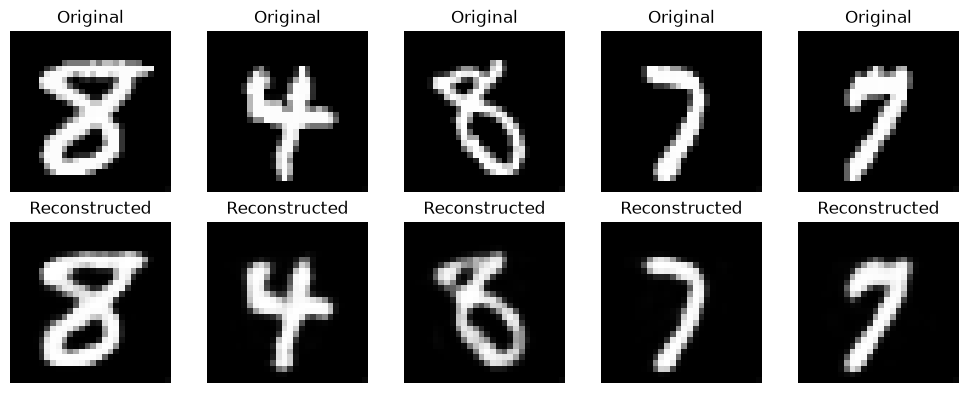

In [1]:

# Assignment 4: Sparse Autoencoder on MNIST

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Load MNIST dataset
df = pd.read_csv("./datasets/MNIST/mnist_784_csv.csv")

# Extract image pixels (ignore labels if present)
if "label" in df.columns:
    X = df.drop(columns=["label"]).values
elif df.shape[1] == 785:
    X = df.iloc[:, 1:].values
else:
    X = df.values

# Normalize images
X = X.astype("float32") / 255.0

# Split dataset
X_train, X_test = train_test_split(
    X, test_size=0.2, random_state=42
)

# Build Sparse Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),

    # Encoder with sparsity constraint
    tf.keras.layers.Dense(
        128, activation='relu',
        activity_regularizer=tf.keras.regularizers.l1(0.0001)
    ),

    # Decoder
    tf.keras.layers.Dense(784, activation='sigmoid')
])

# Compile model
model.compile(optimizer='adam', loss='binary_crossentropy')

# Train autoencoder (input = output)
model.fit(X_train, X_train, epochs=10,
          batch_size=256, validation_split=0.1)

# Reconstruct images
reconstructed = model.predict(X_test[:5], verbose=0)

# Display original and reconstructed images
plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Original")

    plt.subplot(2, 5, i+6)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Reconstructed")

plt.tight_layout()
plt.show()
